# Genetic Algorithm untuk Penjadwalan Ujian

Notebook ringkas untuk mencari jadwal dengan konflik seminimal mungkin.

**Ide GA:** buat banyak jadwal acak (*populasi*), pilih jadwal yang lebih baik, gabungkan (*crossover*), ubah sebagian penempatan (*mutation*), lalu ulangi beberapa generasi.

- Dataset: `usp1e.xlsx` dan `usp1s.xlsx`
- Jumlah slot: 20
- **Cost:** jumlah konflik berbobot antar pasangan ujian. Semakin kecil cost, semakin baik.

## 1. Persiapan dan membaca dataset

Jika file Excel belum ada di folder notebook, kode akan mengunduhnya dari repository dataset.

In [39]:
import os
import time
import urllib.request
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import random

SEED = 42
NUM_SLOTS = 20
random.seed(SEED)
np.random.seed(SEED)

BASE_URL = "https://raw.githubusercontent.com/ravneil/exam-timetable-dataset/main/"
for filename in ["usp1e.xlsx", "usp1s.xlsx"]:
    if not os.path.exists(filename):
        urllib.request.urlretrieve(BASE_URL + filename, filename)

exams = pd.read_excel("usp1e.xlsx", header=None)
students = pd.read_excel("usp1s.xlsx", header=None)

exam_ids = exams.iloc[:, 0].dropna().astype(int).tolist()
exam_index = {exam_id: i for i, exam_id in enumerate(exam_ids)}
n_exams = len(exam_ids)

print(f"Jumlah ujian       : {n_exams:,}")
print(f"Jumlah mahasiswa   : {len(students):,}")
print(f"Jumlah slot waktu  : {NUM_SLOTS}")

Jumlah ujian       : 403
Jumlah mahasiswa   : 18,835
Jumlah slot waktu  : 20


## 2. Membuat matriks konflik

`conflict[i, j]` berisi jumlah mahasiswa yang mengikuti ujian `i` dan ujian `j` sekaligus. Jika dua ujian itu ditempatkan pada slot yang sama, nilai tersebut menambah cost.

In [40]:
conflict = np.zeros((n_exams, n_exams), dtype=np.int32)
student_exams = []

for row in students.to_numpy():
    ids = [exam_index[int(v)] for v in row if pd.notna(v) and int(v) in exam_index]
    student_exams.append(ids)
    for a in range(len(ids)):
        for b in range(a + 1, len(ids)):
            conflict[ids[a], ids[b]] += 1
            conflict[ids[b], ids[a]] += 1

possible_pairs = int(np.count_nonzero(np.triu(conflict, 1)))
total_weight = int(np.triu(conflict, 1).sum())

print(f"Pasangan ujian yang berpotensi konflik : {possible_pairs:,}")
print(f"Total bobot konflik awal              : {total_weight:,}")

Pasangan ujian yang berpotensi konflik : 5,016
Total bobot konflik awal              : 48,280


## 3. Fungsi cost

Satu individu/kromosom adalah jadwal untuk semua ujian. Angka `0` sampai `19` mewakili 20 slot. Fungsi cost menjumlahkan bobot konflik untuk pasangan ujian yang mendapat slot sama.

In [41]:
def random_schedule():
    return np.random.randint(0, NUM_SLOTS, size=n_exams)

def cost(schedule):
    total = 0
    for slot in range(NUM_SLOTS):
        exams_in_slot = np.flatnonzero(schedule == slot)
        if len(exams_in_slot) > 1:
            sub = conflict[np.ix_(exams_in_slot, exams_in_slot)]
            total += int(np.triu(sub, 1).sum())
    return total

# Contoh cost dari satu jadwal acak
print("Contoh cost jadwal acak:", cost(random_schedule()))

Contoh cost jadwal acak: 1998


## 4. Algoritma Genetic Algorithm

- **Seleksi:** pilih induk dari beberapa individu acak; cost terendah menang (*tournament selection*).
- **Crossover:** gabungkan penempatan ujian dari dua induk.
- **Mutation:** pindahkan sebagian ujian ke slot acak.
- **Elitism:** pertahankan beberapa jadwal terbaik agar tidak hilang.

In [42]:
def genetic_algorithm(
    population_size=40,
    generations=150,
    crossover_rate=0.9,
    mutation_rate=0.03,
    elite_count=2,
):
    # Populasi awal berisi jadwal acak
    population = [random_schedule() for _ in range(population_size)]
    scores = [cost(individual) for individual in population]

    best_idx = int(np.argmin(scores))
    best_schedule = population[best_idx].copy()
    best_cost = scores[best_idx]
    history = [best_cost]

    def tournament():
        candidates = random.sample(range(population_size), 3)
        winner = min(candidates, key=lambda idx: scores[idx])
        return population[winner]

    for _ in range(generations):
        # Individu terbaik disalin langsung ke generasi berikutnya
        elite_ids = np.argsort(scores)[:elite_count]
        new_population = [population[i].copy() for i in elite_ids]

        while len(new_population) < population_size:
            parent1 = tournament()
            parent2 = tournament()

            child = parent1.copy()
            if random.random() < crossover_rate:
                mask = np.random.rand(n_exams) < 0.5
                child[mask] = parent2[mask]

            # Mutation: sebagian ujian dipindah ke slot acak
            mutate_mask = np.random.rand(n_exams) < mutation_rate
            n_mutations = int(mutate_mask.sum())
            if n_mutations:
                child[mutate_mask] = np.random.randint(0, NUM_SLOTS, size=n_mutations)

            new_population.append(child)

        population = new_population
        scores = [cost(individual) for individual in population]

        gen_best_idx = int(np.argmin(scores))
        if scores[gen_best_idx] < best_cost:
            best_cost = scores[gen_best_idx]
            best_schedule = population[gen_best_idx].copy()

        history.append(best_cost)

    return best_schedule, best_cost, history

## 5. Menjalankan GA

Parameter di bawah adalah pengaturan awal yang bisa dicoba. Waktu dan hasil cost bergantung pada perangkat dan parameter yang digunakan.

In [43]:
start = time.perf_counter()

best_schedule, best_cost, history = genetic_algorithm(
    population_size=100,
    generations=500,
    crossover_rate=0.9,
    mutation_rate=0.03,
    elite_count=2,
)

runtime = time.perf_counter() - start

print(f"Cost terbaik : {best_cost:,}")
print(f"Waktu proses : {runtime:.2f} detik")
print(f"Generasi     : {len(history) - 1}")

Cost terbaik : 294
Waktu proses : 39.02 detik
Generasi     : 500


## 6. Evaluasi hasil

Selain cost, bagian ini menghitung berapa mahasiswa yang masih memiliki setidaknya dua ujian pada slot yang sama. Satu mahasiswa dihitung satu kali meskipun mengalami lebih dari satu bentrok.

Mahasiswa yang bentrok : 292 dari 18,835
Mahasiswa tanpa bentrok: 18,543 dari 18,835
Pasangan ujian bentrok : 159
Cost berbobot          : 294


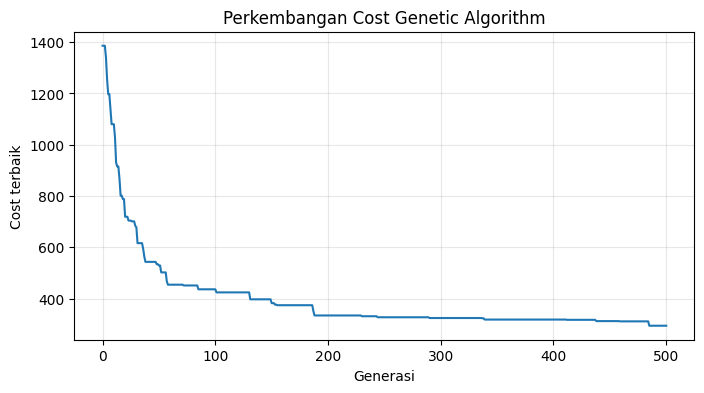

In [44]:
def count_students_with_conflict(schedule):
    return sum(
        1 for ids in student_exams
        if len(ids) != len(set(schedule[exam_idx] for exam_idx in ids))
    )

students_conflict = count_students_with_conflict(best_schedule)
students_safe = len(student_exams) - students_conflict
same_slot = best_schedule[:, None] == best_schedule[None, :]
conflicting_pairs = int(np.count_nonzero(np.triu((conflict > 0) & same_slot, 1)))

print(f"Mahasiswa yang bentrok : {students_conflict:,} dari {len(student_exams):,}")
print(f"Mahasiswa tanpa bentrok: {students_safe:,} dari {len(student_exams):,}")
print(f"Pasangan ujian bentrok : {conflicting_pairs:,}")
print(f"Cost berbobot          : {best_cost:,}")

plt.figure(figsize=(8, 4))
plt.plot(range(len(history)), history)
plt.xlabel("Generasi")
plt.ylabel("Cost terbaik")
plt.title("Perkembangan Cost Genetic Algorithm")
plt.grid(alpha=0.3)
plt.show()